# 01 · The forecasting problem

**Goal of this notebook:** define precisely what is being predicted, build the simplest possible forecast, and learn how to score it fairly.

We start with the **clean** scenario so that nothing but the forecasting problem is in the way. Notebook 03 brings in the mess.

Text(0.5, 0, 'week index')

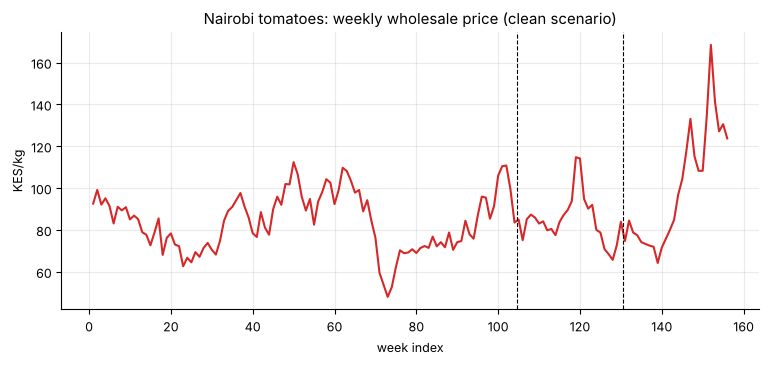

In [1]:
from tutorial_utils import *
style()
clean = load_panel("clean")
s = clean[clean.series == "MKT-01|CRP-02"].set_index("week_index")      # Nairobi tomatoes
ax = s.wholesale_price_kes_kg.plot(color="#d62828", title="Nairobi tomatoes: weekly wholesale price (clean scenario)")
for x, lab in [(TRAIN_END + .5, "train | validation"), (VAL_END + .5, "validation | test")]:
    ax.axvline(x, color="k", ls="--", lw=.8)
ax.set_ylabel("KES/kg"); ax.set_xlabel("week index")

## Origins, horizons and targets

A forecast is made **at an origin** `t` (the end of week `t`) **for a target week** `t + h`. With three horizons and 156 weeks,
every series produces many (origin, horizon, target) rows. Let us look at the rows for one origin.

In [2]:
origin = 100
price = s.wholesale_price_kes_kg
rows = []
for h in HORIZONS:
    rows.append(dict(origin_week=origin, horizon=h, target_week=origin + h, latest_price_at_origin=price[origin],
                     actual_price_at_target=price[origin + h]))
tbl = pd.DataFrame(rows)
tbl["naive_forecast"] = tbl.latest_price_at_origin
tbl["abs_error"] = (tbl.actual_price_at_target - tbl.naive_forecast).abs()
tbl.round(2)

,origin_week,horizon,target_week,latest_price_at_origin,actual_price_at_target,naive_forecast,abs_error
0,100,1,101,105.95,110.49,105.95,4.54
1,100,2,102,105.95,110.80,105.95,4.85
2,100,4,104,105.95,83.56,105.95,22.39


The **naive forecast** says: "the price in `h` weeks will equal the price now". It uses no model at all.
Notice that the error is larger for the longer horizon - there is simply more time for things to change.

Let us measure that over *all* origins of this series (clean scenario, training period only: origins 14 … 104 − h).

1     5.97
2     8.16
4    10.34
Name: MAE (KES/kg), dtype: float64

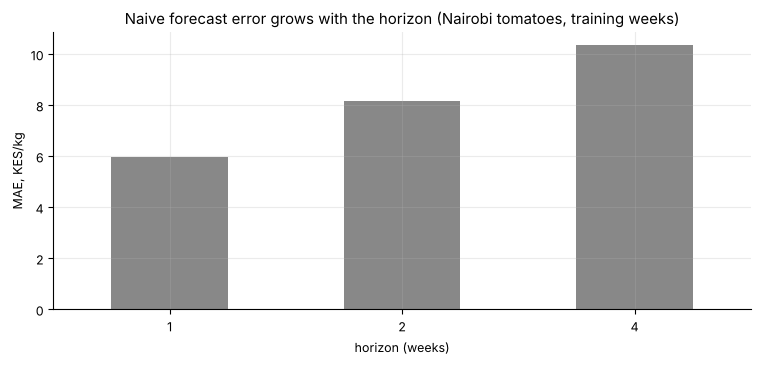

In [3]:
def naive_abs_errors(price: pd.Series, h: int, first=14, last=TRAIN_END):
    origins = np.arange(first, last - h + 1)
    return pd.Series(np.abs(price.values[origins + h - 1] - price.values[origins - 1]), index=origins)   # week w is element w-1

res = pd.Series({h: naive_abs_errors(price, h).mean() for h in HORIZONS}, name="MAE (KES/kg)")
ax = res.plot.bar(rot=0, color="#888", title="Naive forecast error grows with the horizon (Nairobi tomatoes, training weeks)")
ax.set_xlabel("horizon (weeks)"); ax.set_ylabel("MAE, KES/kg")
res.round(2)

## Three ways to score a forecast

* **MAE** = mean of |actual − forecast|, in KES/kg. Easy to read, but *scale dependent*.
* **RMSE** punishes large misses more. **WAPE** = Σ|error| / Σ actual: a percentage that can be compared across crops.
* **Skill vs naive** = 1 − MAE / MAE_naive. Scale-free *and* it directly asks the question "is the model better than doing nothing?"

Why does scale matter? Compare the naive error for all four crops over the **validation** window (origins 105 … 130).

In [4]:
price_w = wide(clean, "wholesale_price_kes_kg")          # weeks x series
def naive_mae_by_series(h, lo=TRAIN_END + 1, hi=VAL_END):
    origins = np.arange(lo, eval_hi(h, hi) + 1)
    err = (price_w.loc[origins + h].values - price_w.loc[origins].values)
    return pd.Series(np.abs(err).mean(0), index=price_w.columns)

mae_tab = pd.DataFrame({h: naive_mae_by_series(h) for h in HORIZONS})
mae_tab["crop"] = [CROPS[c.split("|")[1]] for c in mae_tab.index]
by_crop = mae_tab.groupby("crop")[list(HORIZONS)].mean()
level = clean[clean.week_index.between(TRAIN_END + 1, VAL_END)].groupby(clean.crop_id.map(CROPS)).wholesale_price_kes_kg.mean()
by_crop["average price"] = level
by_crop["h=4 error as % of price"] = by_crop[4] / by_crop["average price"] * 100
by_crop.round(2)

,1,2,4,average price,h=4 error as % of price
crop,,,,,
Irish potatoes,1.97,3.14,5.11,51.12,10.00
Maize,0.82,1.27,2.09,58.70,3.55
Onions,2.03,3.18,5.01,86.48,5.79
Tomatoes,6.59,9.55,12.14,77.94,15.58


**Reading the table.** Tomatoes have by far the largest absolute error, but part of that is simply that they are the most
volatile and a more expensive crop. Averaging MAEs across crops would let tomatoes dominate. Throughout the experiment we therefore
also report scale-free numbers (WAPE, skill vs naive) and break results down by crop.

## A model has to beat "do nothing"
Here is a second simple forecast - the **4-week moving average** of past prices - and its skill versus naive:

In [5]:
def moving_average_mae(h, k=4, lo=TRAIN_END + 1, hi=VAL_END):
    origins = np.arange(lo, eval_hi(h, hi) + 1)
    ma = price_w.rolling(k).mean().loc[origins].values
    return np.abs(price_w.loc[origins + h].values - ma).mean()

skill = pd.Series({h: 1 - moving_average_mae(h) / naive_mae_by_series(h).mean() for h in HORIZONS}, name="skill of MA(4) vs naive")
print((skill * 100).round(1).to_string(), "\n(negative = worse than naive)")

1   -47.3
2   -20.8
4    -7.4 
(negative = worse than naive)


Averaging past prices *adds lag*: after a move, the average still remembers the old level. Prices here are persistent, so the most recent value
is the best simple summary. This is the first lesson of the project: **simple baselines are strong, and "sophisticated" is not the same as "better".**

## What the clean scenario hides
We ignored three real-world complications, which the next notebooks address:
1. In real data some prices are **missing** or **wrong** (notebook 03).
2. Some indicators arrive **late**, so "what is known at the origin" is subtler than "everything up to week t" (notebook 05).
3. The evaluation windows must be **chronological** and leakage-free (notebook 06).

## Exercises
1. Change `origin` to 140 (inside the test window). Is the naive error bigger or smaller than at week 100? Why might that be? (Hint: events - see notebook 02.)
2. Compute the naive forecast error for **maize** in Eldoret (`MKT-03|CRP-01`) at each horizon. How does the ratio MAE(h=4)/MAE(h=1) compare with tomatoes? What does that say about persistence?
3. Implement a "drift" forecast: `price_t + h × (average weekly change over the last 8 weeks)`. Does it beat naive at h=4?

**Where this lives in the pipeline:** the (series, origin, horizon, target) rows are built in `src/agriprice/features.py` (`FeatureStore.frame`);
metrics are in `src/agriprice/metrics.py`; the naive and moving-average baselines in `src/agriprice/models.py` (`baseline_predictions`).